<a href="https://colab.research.google.com/github/Muhamadzulfikar/siakad-analysis/blob/master/Akreditasi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Libary

In [159]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
from google.colab import files
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Mahasiswa Aktif 2022 - 2026

In [ ]:
kagglehub.dataset_download("muhamadzulfikar/mahasiswa-aktif")

Using Colab cache for faster access to the 'mahasiswa-aktif' dataset.


'/kaggle/input/mahasiswa-aktif'

In [ ]:
mahasiswaAktifDf = pd.read_csv('/kaggle/input/mahasiswa-aktif/mahasiswa-aktif.csv')



In [157]:
mahasiswaAktifDf

,tahun_angkatan,program_studi,mahasiswa_aktif
0,2026,Bisnis Digital,50
1,2026,Desain Komunikasi Visual,54
2,2026,Manajemen Rekayasa,39
3,2026,Matematika,4
4,2026,Perdagangan Internasional,92
5,2026,Sistem Informasi,68
6,2026,Teknik Industri,279
7,2026,Teknik Komputer,56
8,2025,Bisnis Digital,39
9,2025,Desain Komunikasi Visual,64


## Mahasiswa Aktif Semua Prodi

### Table

In [149]:
mhsAktifAllDf = mahasiswaAktifDf.groupby('tahun_angkatan')['mahasiswa_aktif'].sum().reset_index()
mhsAktifAllDf = mhsAktifAllDf.rename(columns={
    'tahun_angkatan': 'Tahun Angkatan',
    'mahasiswa_aktif': 'Jumlah Mahasiswa Aktif',
})

mhsAktifAllDf.style.hide(axis='index')

Tahun Angkatan,Jumlah Mahasiswa Aktif
2022,287
2023,267
2024,473
2025,547
2026,642


### Diagram Batang

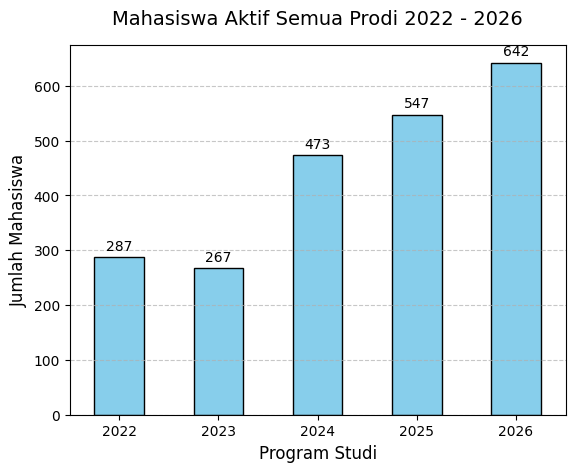

In [151]:
mhsAktifAllPlt = mhsAktifAllDf.plot(
    x='Tahun Angkatan',
    y='Jumlah Mahasiswa Aktif',
    kind='bar',
    color='skyblue',
    edgecolor='black',
    legend=False
)

mhsAktifAllPlt.set_title(
    'Mahasiswa Aktif Semua Prodi 2022 - 2026',
    fontsize=14,
    pad=15
)
mhsAktifAllPlt.set_xlabel(
    'Program Studi',
    fontsize=12
)
mhsAktifAllPlt.set_ylabel(
    'Jumlah Mahasiswa',
    fontsize=12
)
mhsAktifAllPlt.bar_label(
    mhsAktifAllPlt.containers[0], padding=3, fontsize=10, fmt='%d'
)

mhsAktifAllPlt.tick_params(axis='x', rotation=0)
mhsAktifAllPlt.grid(axis='y', linestyle='--', alpha=0.7)

### Download Table

In [155]:
mhsAktifAllDf.to_excel('mahasiswa-aktif-semua-prodi.xlsx', index=False)
files.download('mahasiswa-aktif-semua-prodi.xlsx')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Perbandingan Tren Semua Program Studi (Grouped Bar Chart)

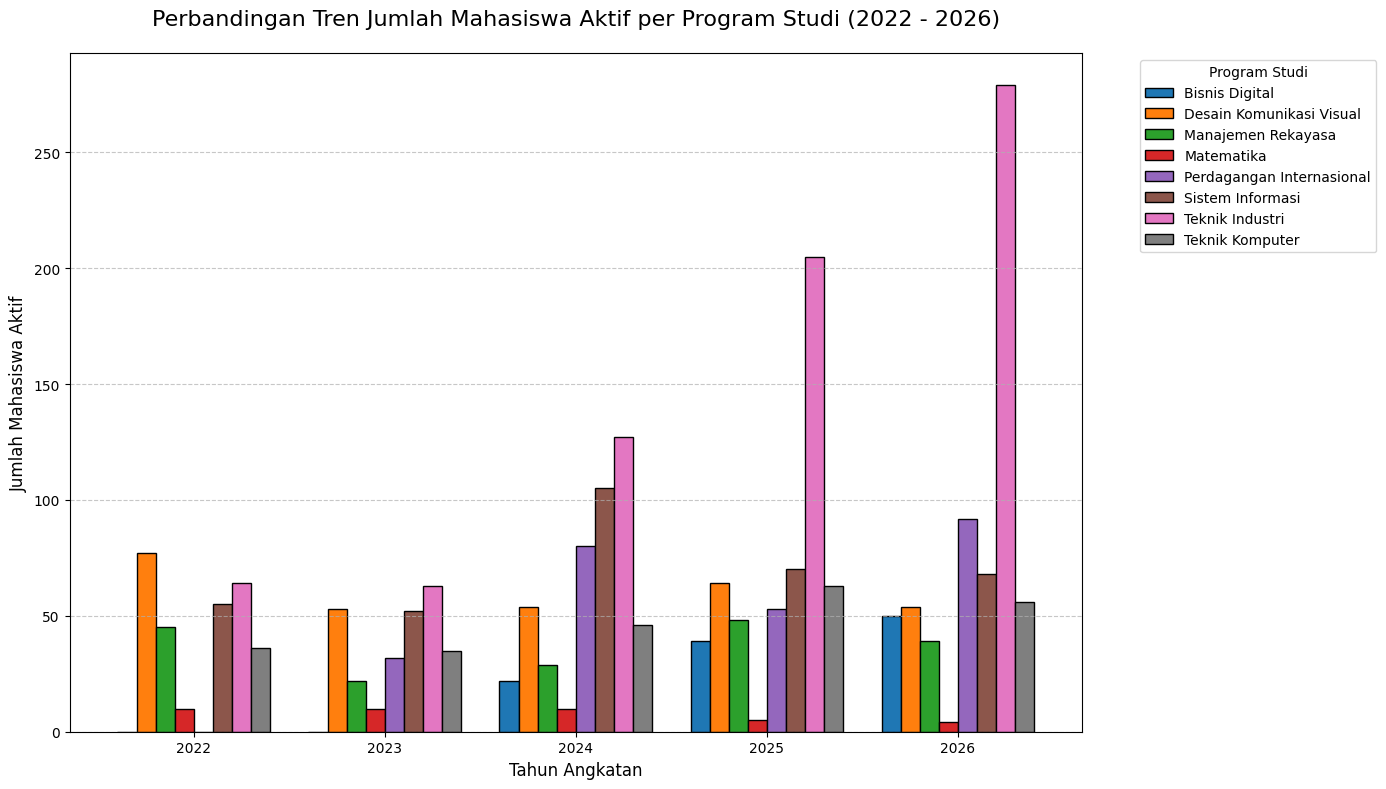

In [161]:
pivot_df = mahasiswaAktifDf.pivot(index='tahun_angkatan', columns='program_studi', values='mahasiswa_aktif').fillna(0)

# Plotting
fig, ax = plt.subplots(figsize=(14, 8))
pivot_df.plot(kind='bar', ax=ax, width=0.8, edgecolor='black')

ax.set_title('Perbandingan Tren Jumlah Mahasiswa Aktif per Program Studi (2022 - 2026)', fontsize=16, pad=20)
ax.set_xlabel('Tahun Angkatan', fontsize=12)
ax.set_ylabel('Jumlah Mahasiswa Aktif', fontsize=12)
ax.legend(title='Program Studi', bbox_to_anchor=(1.05, 1), loc='upper left')
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Mahasiswa Aktif Prodi Matematika

### Table

In [ ]:
mhsAktifMtkDf = mahasiswaAktifDf.loc[
    mahasiswaAktifDf['program_studi'] == 'Matematika',
    ['tahun_angkatan', 'mahasiswa_aktif']
].rename(columns={
    'tahun_angkatan': 'Tahun Angkatan',
    'mahasiswa_aktif': 'Jumlah Mahasiswa Aktif'
})

mhsAktifMtkDf.style.hide(axis='index')

Tahun Angkatan,Jumlah Mahasiswa Aktif
2026,4
2025,5
2024,10
2023,10
2022,10


### Diagram Batang



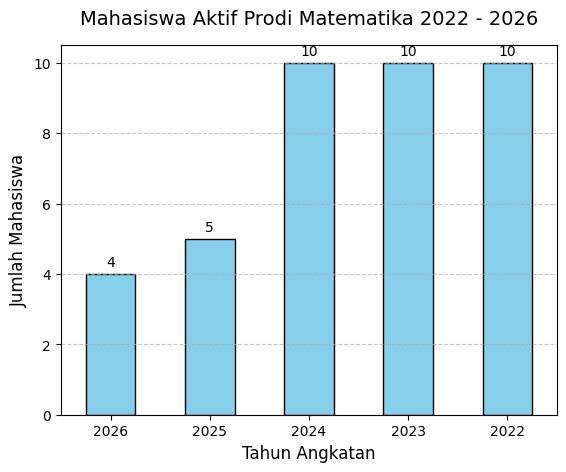

In [132]:
mhsAktifMtkPlt = mhsAktifMtkDf.plot(
    x='Tahun Angkatan',
    y='Jumlah Mahasiswa Aktif',
    kind='bar',
    color='skyblue',
    edgecolor='black',
    legend=False
)

mhsAktifMtkPlt.set_title(
    'Mahasiswa Aktif Prodi Matematika 2022 - 2026',
    fontsize=14,
    pad=15
)
mhsAktifMtkPlt.set_xlabel(
    'Tahun Angkatan',
    fontsize=12
)
mhsAktifMtkPlt.set_ylabel(
    'Jumlah Mahasiswa',
    fontsize=12
)
mhsAktifMtkPlt.bar_label(
    mhsAktifMtkPlt.containers[0], padding=3, fontsize=10, fmt='%d'
)

mhsAktifMtkPlt.tick_params(axis='x', rotation=0)
mhsAktifMtkPlt.grid(axis='y', linestyle='--', alpha=0.7)

### Download Table

In [ ]:
mhsAktifMtkDf.to_excel('mahasiswa-aktif-matematika.xlsx', index=False)
files.download('mahasiswa-aktif-matematika.xlsx')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Mahasiswa Aktif Prodi Teknik Komputer

### Table

In [ ]:
mhsAktifTkDf = mahasiswaAktifDf.loc[
    mahasiswaAktifDf['program_studi'] == 'Teknik Komputer',
    ['tahun_angkatan', 'mahasiswa_aktif']
].rename(columns={
    'tahun_angkatan': 'Tahun Angkatan',
    'mahasiswa_aktif': 'Jumlah Mahasiswa Aktif'
})

mhsAktifTkDf.style.hide(axis='index')

Tahun Angkatan,Jumlah Mahasiswa Aktif
2026,56
2025,63
2024,46
2023,35
2022,36


### Diagram Batang

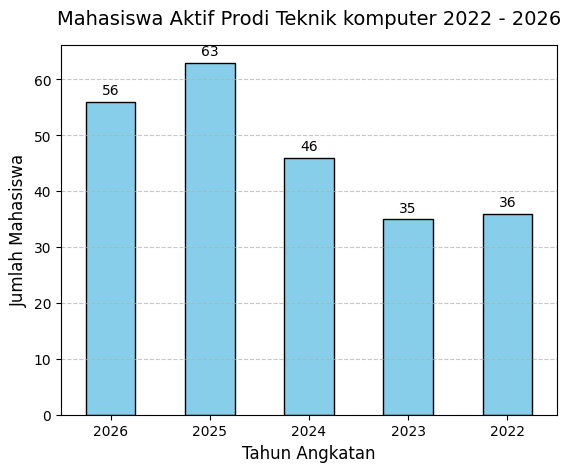

In [ ]:
mhsAktifTkPlt = mhsAktifTkDf.plot(
    x='Tahun Angkatan',
    y='Jumlah Mahasiswa Aktif',
    kind='bar',
    color='skyblue',
    edgecolor='black',
    legend=False
)

mhsAktifTkPlt.set_title(
    'Mahasiswa Aktif Prodi Teknik komputer 2022 - 2026',
    fontsize=14,
    pad=15
)
mhsAktifTkPlt.set_xlabel(
    'Tahun Angkatan',
    fontsize=12
)
mhsAktifTkPlt.set_ylabel(
    'Jumlah Mahasiswa',
    fontsize=12
)
mhsAktifTkPlt.bar_label(
    mhsAktifTkPlt.containers[0], padding=3, fontsize=10, fmt='%d'
)

mhsAktifTkPlt.tick_params(axis='x', rotation=0)
mhsAktifTkPlt.grid(axis='y', linestyle='--', alpha=0.7)

### Download Table

In [ ]:
mhsAktifTkDf.to_excel('mahasiswa-aktif-teknik-komputer.xlsx', index=False)
files.download('mahasiswa-aktif-teknik-komputer.xlsx')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Mahasiswa Aktif Prodi Teknik Industri

### Table

In [ ]:
mhsAktifTiDf = mahasiswaAktifDf.loc[
    mahasiswaAktifDf['program_studi'] == 'Teknik Industri',
    ['tahun_angkatan', 'mahasiswa_aktif']
].rename(columns={
    'tahun_angkatan': 'Tahun Angkatan',
    'mahasiswa_aktif': 'Jumlah Mahasiswa Aktif'
})

mhsAktifTiDf.style.hide(axis='index')

Tahun Angkatan,Jumlah Mahasiswa Aktif
2026,279
2025,205
2024,127
2023,63
2022,64


### Diagram Batang

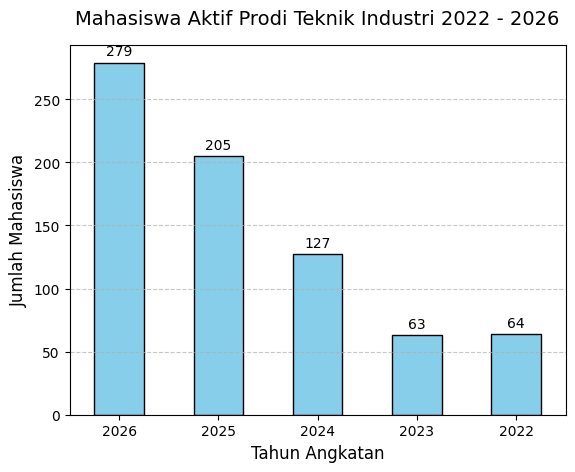

In [ ]:
mhsAktifTiPlt = mhsAktifTiDf.plot(
    x='Tahun Angkatan',
    y='Jumlah Mahasiswa Aktif',
    kind='bar',
    color='skyblue',
    edgecolor='black',
    legend=False
)

mhsAktifTiPlt.set_title(
    'Mahasiswa Aktif Prodi Teknik Industri 2022 - 2026',
    fontsize=14,
    pad=15
)
mhsAktifTiPlt.set_xlabel(
    'Tahun Angkatan',
    fontsize=12
)
mhsAktifTiPlt.set_ylabel(
    'Jumlah Mahasiswa',
    fontsize=12
)
mhsAktifTiPlt.bar_label(
    mhsAktifTiPlt.containers[0], padding=3, fontsize=10, fmt='%d'
)

mhsAktifTiPlt.tick_params(axis='x', rotation=0)
mhsAktifTiPlt.grid(axis='y', linestyle='--', alpha=0.7)

### Download Table

In [ ]:
mhsAktifTiDf.to_excel('mahasiswa-aktif-teknik-industri.xlsx', index=False)
files.download('mahasiswa-aktif-teknik-industri.xlsx')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Mahasiswa Aktif Prodi Sistem Informasi

### Table

In [ ]:
mhsAktifSiDf = mahasiswaAktifDf.loc[
    mahasiswaAktifDf['program_studi'] == 'Sistem Informasi',
    ['tahun_angkatan', 'mahasiswa_aktif']
].rename(columns={
    'tahun_angkatan': 'Tahun Angkatan',
    'mahasiswa_aktif': 'Jumlah Mahasiswa Aktif'
})

mhsAktifTiDf.style.hide(axis='index')

Tahun Angkatan,Jumlah Mahasiswa Aktif
2026,279
2025,205
2024,127
2023,63
2022,64


### Diagram Batang

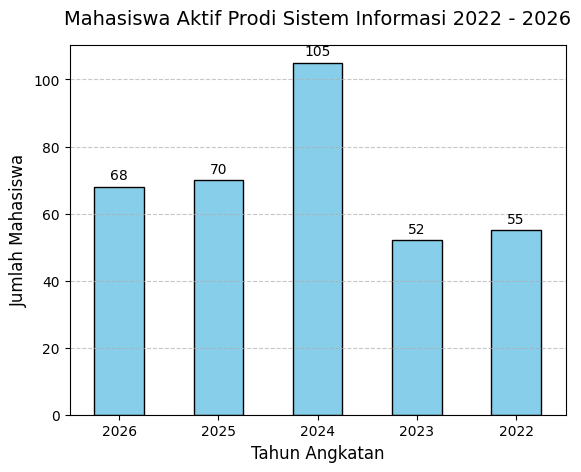

In [163]:
mhsAktifSiPlt = mhsAktifSiDf.plot(
    x='Tahun Angkatan',
    y='Jumlah Mahasiswa Aktif',
    kind='bar',
    color='skyblue',
    edgecolor='black',
    legend=False
)

mhsAktifSiPlt.set_title(
    'Mahasiswa Aktif Prodi Sistem Informasi 2022 - 2026',
    fontsize=14,
    pad=15
)
mhsAktifSiPlt.set_xlabel(
    'Tahun Angkatan',
    fontsize=12
)
mhsAktifSiPlt.set_ylabel(
    'Jumlah Mahasiswa',
    fontsize=12
)
mhsAktifSiPlt.bar_label(
    mhsAktifSiPlt.containers[0], padding=3, fontsize=10, fmt='%d'
)

mhsAktifSiPlt.tick_params(axis='x', rotation=0)
mhsAktifSiPlt.grid(axis='y', linestyle='--', alpha=0.7)

### Download Table

In [ ]:
mhsAktifSiDf.to_excel('mahasiswa-aktif-sistem-informasi.xlsx', index=False)
files.download('mahasiswa-aktif-sistem-informasi.xlsx')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Mahasiswa Aktif Prodi Manajemen Rekayasa

### Table

In [ ]:
mhsAktifMrDf = mahasiswaAktifDf.loc[
    mahasiswaAktifDf['program_studi'] == 'Manajemen Rekayasa',
    ['tahun_angkatan', 'mahasiswa_aktif']
].rename(columns={
    'tahun_angkatan': 'Tahun Angkatan',
    'mahasiswa_aktif': 'Jumlah Mahasiswa Aktif'
})

mhsAktifMrDf.style.hide(axis='index')

Tahun Angkatan,Jumlah Mahasiswa Aktif
2026,39
2025,48
2024,29
2023,22
2022,45


### Diagram Batang

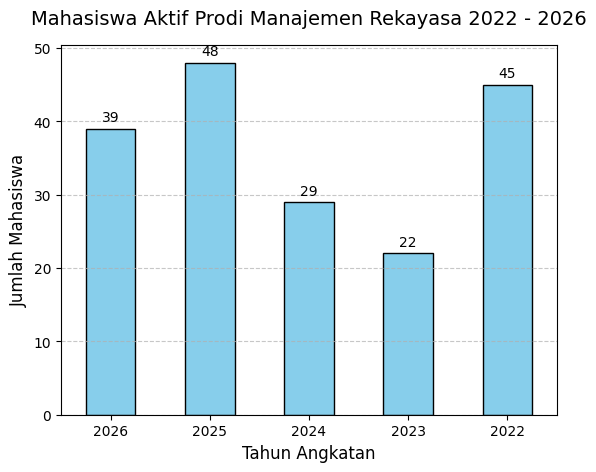

In [ ]:
mhsAktifMrPlt = mhsAktifMrDf.plot(
    x='Tahun Angkatan',
    y='Jumlah Mahasiswa Aktif',
    kind='bar',
    color='skyblue',
    edgecolor='black',
    legend=False
)

mhsAktifMrPlt.set_title(
    'Mahasiswa Aktif Prodi Manajemen Rekayasa 2022 - 2026',
    fontsize=14,
    pad=15
)
mhsAktifMrPlt.set_xlabel(
    'Tahun Angkatan',
    fontsize=12
)
mhsAktifMrPlt.set_ylabel(
    'Jumlah Mahasiswa',
    fontsize=12
)
mhsAktifMrPlt.bar_label(
    mhsAktifMrPlt.containers[0], padding=3, fontsize=10, fmt='%d'
)

mhsAktifMrPlt.tick_params(axis='x', rotation=0)
mhsAktifMrPlt.grid(axis='y', linestyle='--', alpha=0.7)

### Download Table

In [ ]:
mhsAktifMrDf.to_excel('mahasiswa-aktif-manajemen-rekayasa.xlsx', index=False)
files.download('mahasiswa-aktif-manajemen-rekayasa.xlsx')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Mahasiswa Aktif Prodi Desain Komunikasi Visual

### Table

In [ ]:
mhsAktifDkvDf = mahasiswaAktifDf.loc[
    mahasiswaAktifDf['program_studi'] == 'Desain Komunikasi Visual',
    ['tahun_angkatan', 'mahasiswa_aktif']
].rename(columns={
    'tahun_angkatan': 'Tahun Angkatan',
    'mahasiswa_aktif': 'Jumlah Mahasiswa Aktif'
})

mhsAktifDkvDf.style.hide(axis='index')

Tahun Angkatan,Jumlah Mahasiswa Aktif
2026,54
2025,64
2024,54
2023,53
2022,77


### Diagram Batang

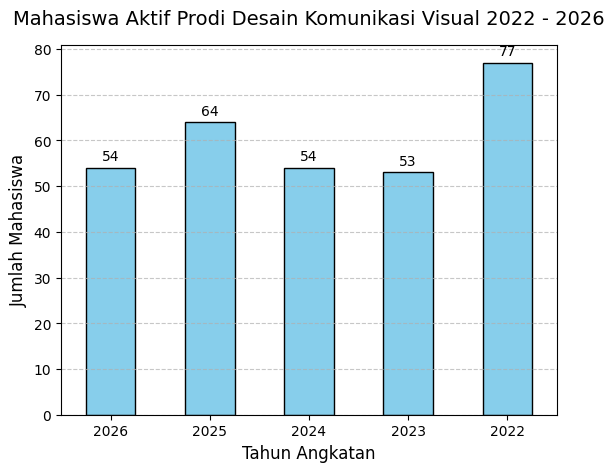

In [ ]:
mhsAktifDkvPlt = mhsAktifDkvDf.plot(
    x='Tahun Angkatan',
    y='Jumlah Mahasiswa Aktif',
    kind='bar',
    color='skyblue',
    edgecolor='black',
    legend=False
)

mhsAktifDkvPlt.set_title(
    'Mahasiswa Aktif Prodi Desain Komunikasi Visual 2022 - 2026',
    fontsize=14,
    pad=15
)
mhsAktifDkvPlt.set_xlabel(
    'Tahun Angkatan',
    fontsize=12
)
mhsAktifDkvPlt.set_ylabel(
    'Jumlah Mahasiswa',
    fontsize=12
)
mhsAktifDkvPlt.bar_label(
    mhsAktifDkvPlt.containers[0], padding=3, fontsize=10, fmt='%d'
)

mhsAktifDkvPlt.tick_params(axis='x', rotation=0)
mhsAktifDkvPlt.grid(axis='y', linestyle='--', alpha=0.7)

### Download Table

In [ ]:
mhsAktifDkvDf.to_excel('mahasiswa-aktif-desain-komunikasi-visual.xlsx', index=False)
files.download('mahasiswa-aktif-desain-komunikasi-visual.xlsx')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Mahasiswa Aktif Prodi Perdagangan Internasional

### Table

In [129]:
mhsAktifPiDf = mahasiswaAktifDf.loc[
    mahasiswaAktifDf['program_studi'] == 'Perdagangan Internasional',
    ['tahun_angkatan', 'mahasiswa_aktif']
].rename(columns={
    'tahun_angkatan': 'Tahun Angkatan',
    'mahasiswa_aktif': 'Jumlah Mahasiswa Aktif'
})

mhsAktifPiDf.style.hide(axis='index')

Tahun Angkatan,Jumlah Mahasiswa Aktif
2026,92
2025,53
2024,80
2023,32


### Diagram Batang

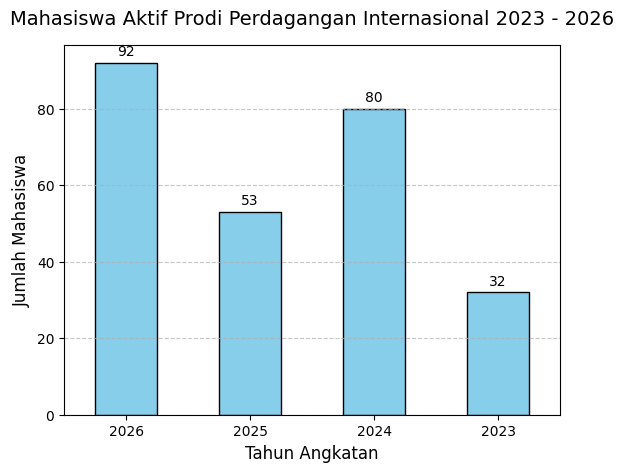

In [136]:
mhsAktifPiPlt = mhsAktifPiDf.plot(
    x='Tahun Angkatan',
    y='Jumlah Mahasiswa Aktif',
    kind='bar',
    color='skyblue',
    edgecolor='black',
    legend=False
)

mhsAktifPiPlt.set_title(
    'Mahasiswa Aktif Prodi Perdagangan Internasional 2023 - 2026',
    fontsize=14,
    pad=15
)
mhsAktifPiPlt.set_xlabel(
    'Tahun Angkatan',
    fontsize=12
)
mhsAktifPiPlt.set_ylabel(
    'Jumlah Mahasiswa',
    fontsize=12
)
mhsAktifPiPlt.bar_label(
    mhsAktifPiPlt.containers[0], padding=3, fontsize=10, fmt='%d'
)

mhsAktifPiPlt.tick_params(axis='x', rotation=0)
mhsAktifPiPlt.grid(axis='y', linestyle='--', alpha=0.7)

### Download Table

In [131]:
mhsAktifPiDf.to_excel('mahasiswa-aktif-perdagangan-internasional.xlsx', index=False)
files.download('mahasiswa-aktif-perdagangan-internasional.xlsx')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Mahasiswa Aktif Prodi Bisnis Digital

### Table

In [134]:
mhsAktifBdDf = mahasiswaAktifDf.loc[
    mahasiswaAktifDf['program_studi'] == 'Bisnis Digital',
    ['tahun_angkatan', 'mahasiswa_aktif']
].rename(columns={
    'tahun_angkatan': 'Tahun Angkatan',
    'mahasiswa_aktif': 'Jumlah Mahasiswa Aktif'
})

mhsAktifBdDf.style.hide(axis='index')

Tahun Angkatan,Jumlah Mahasiswa Aktif
2026,50
2025,39
2024,22


### Diagram Batang

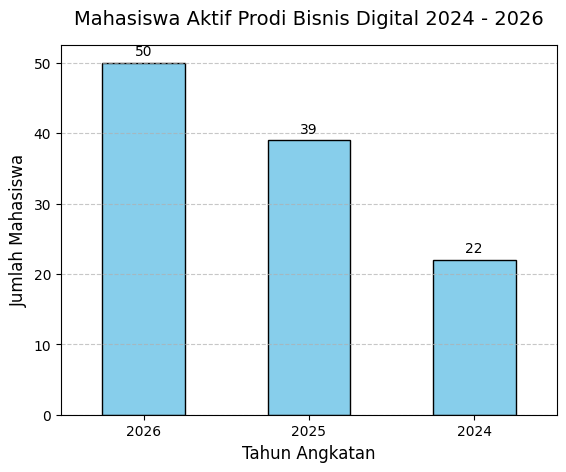

In [135]:
mhsAktifBdPlt = mhsAktifBdDf.plot(
    x='Tahun Angkatan',
    y='Jumlah Mahasiswa Aktif',
    kind='bar',
    color='skyblue',
    edgecolor='black',
    legend=False
)

mhsAktifBdPlt.set_title(
    'Mahasiswa Aktif Prodi Bisnis Digital 2024 - 2026',
    fontsize=14,
    pad=15
)
mhsAktifBdPlt.set_xlabel(
    'Tahun Angkatan',
    fontsize=12
)
mhsAktifBdPlt.set_ylabel(
    'Jumlah Mahasiswa',
    fontsize=12
)
mhsAktifBdPlt.bar_label(
    mhsAktifBdPlt.containers[0], padding=3, fontsize=10, fmt='%d'
)

mhsAktifBdPlt.tick_params(axis='x', rotation=0)
mhsAktifBdPlt.grid(axis='y', linestyle='--', alpha=0.7)

### Download Table

In [160]:
mhsAktifBdDf.to_excel('mahasiswa-aktif-bisnis-digital.xlsx', index=False)
files.download('mahasiswa-aktif-bisnis-digital.xlsx')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>